## How to read this notebook

Monte Carlo VaR for the Nifty 50, section 6 of the report. The version the report discusses is the **second attempt** (the last code cells): a 90-day lookback, 10,000 normal draws, and a 99% VaR equal to the 1st percentile of

```text
simulated return = mean(last 90 log returns) + std(last 90 log returns) * z
```

The next day's actual log return is a violation when it falls below that percentile. The report's violation rate is **2.4%**, against the 1% a 99% VaR implies, so the **AE ratio is 2.4**.

The first `calculate_volatility` function is an earlier batch design (90-day lookback, 21-day blocks, 1,000 draws, portfolio scaled to ₹10,00,000). Kupiec, Christoffersen, and conditional coverage run on the second attempt's violation list.

Both loads use `data/Nifty50_data.xlsx`. The second cell originally pointed at `nifty 20 yr.xlsx` on a local drive; that file is not in this repository, and the shared 2005–2023 workbook is the sample the report describes.


In [89]:
# Data, plots, diagnostics, and the normal distribution used to draw shocks.
# arch and the Ljung-Box import belong to residual checks and are not
# required for the Monte Carlo percentile itself.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch import arch_model
from scipy.stats import norm


In [90]:
# Shared dataset locator.
# The workbook and the two-year CSV live in the project data/ folder.
# Running this notebook from a method folder (Historical, GARCH, ...) or from
# the project root both resolve. Machine-specific paths from the original
# Colab / local drives are no longer required.
from pathlib import Path

def find_nifty_file(filename="Nifty50_data.xlsx"):
    """Return the first existing copy of a file under data/ or the working directory."""
    here = Path.cwd().resolve()
    candidates = [
        here / "data" / filename,
        here.parent / "data" / filename,
        here / filename,
    ]
    for path in candidates:
        if path.exists():
            return str(path.resolve())
    raise FileNotFoundError(
        f"Could not find {filename}. Open the notebook from the project folder "
        "or from its method folder so that data/ is visible."
    )

NIFTY_PATH = find_nifty_file("Nifty50_data.xlsx")
print("Using dataset:", NIFTY_PATH)

file_path = NIFTY_PATH  # was F:/M.sc/4th sem/FCP/Nifty50_data.xlsx
data = pd.read_excel(file_path)


In [91]:
# Keep the two columns every later cell uses: Dates, NIFTY Index.

df = data[['Dates','NIFTY Index']]


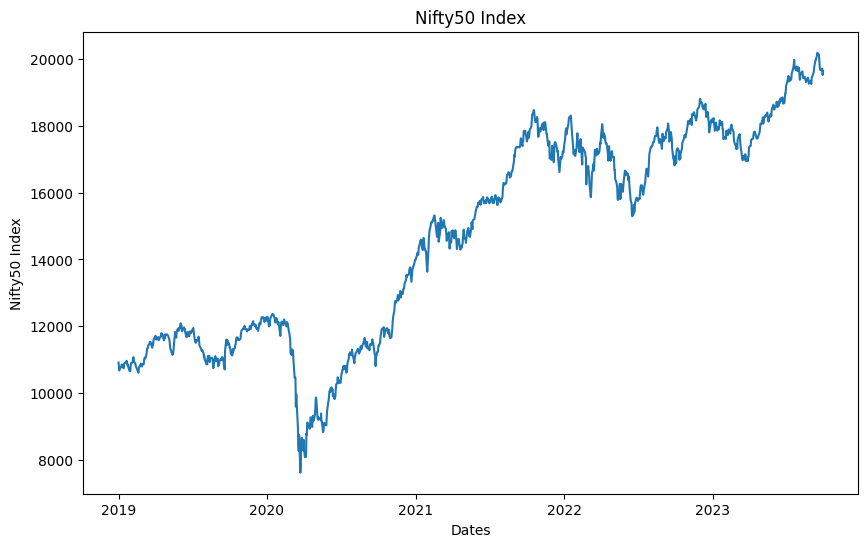

In [92]:
# Index level, 2005-2023. The VaR work is done on log returns, not on the level.

plt.figure(figsize=(10,6))
plt.plot(df['Dates'],df['NIFTY Index'])
plt.title('Nifty50 Index')
plt.xlabel('Dates')
plt.ylabel('Nifty50 Index')
plt.show()


In [93]:
# r_t = ln(P_t / P_{t-1}). The first row is NaN and is dropped inside the loops.

df['log_return'] = np.log(df['NIFTY Index']/df['NIFTY Index'].shift(1))


In [94]:
# Confirm the column exists before plotting.

df.head()


,Dates,NIFTY Index,log_return
0,2019-01-01,10910.10,NaN
1,2019-01-02,10792.50,-0.010838
2,2019-01-03,10672.25,-0.011205
3,2019-01-04,10727.35,0.005150
4,2019-01-07,10771.80,0.004135


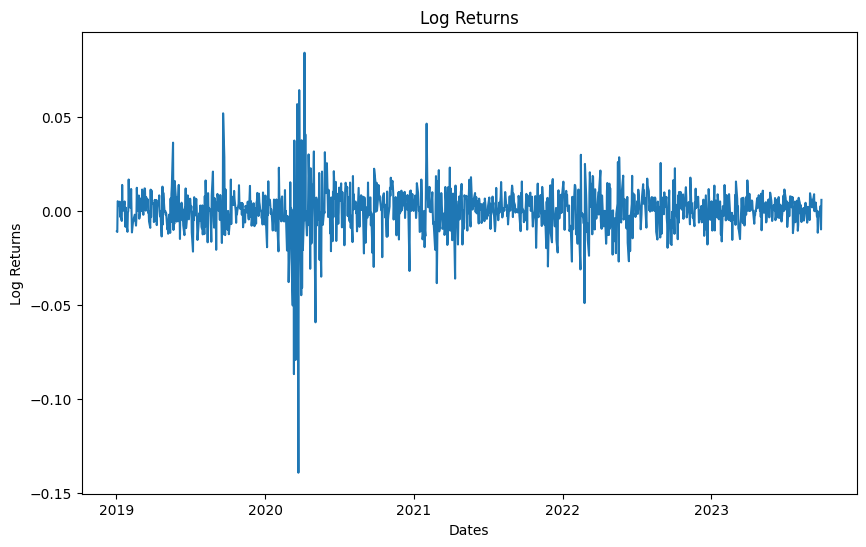

In [95]:
# Log-return path. Clusters of large moves are the stretches where a
# 90-day volatility estimate changes quickly.

plt.figure(figsize=(10,6)) 
plt.plot(df['Dates'],df['log_return'])
plt.title('Log Returns')
plt.xlabel('Dates')
plt.ylabel('Log Returns')
plt.show()


C:\Users\shree\AppData\Local\Temp\ipykernel_13532\3896868204.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['log_return'].dropna(),bins=5,color='purple')


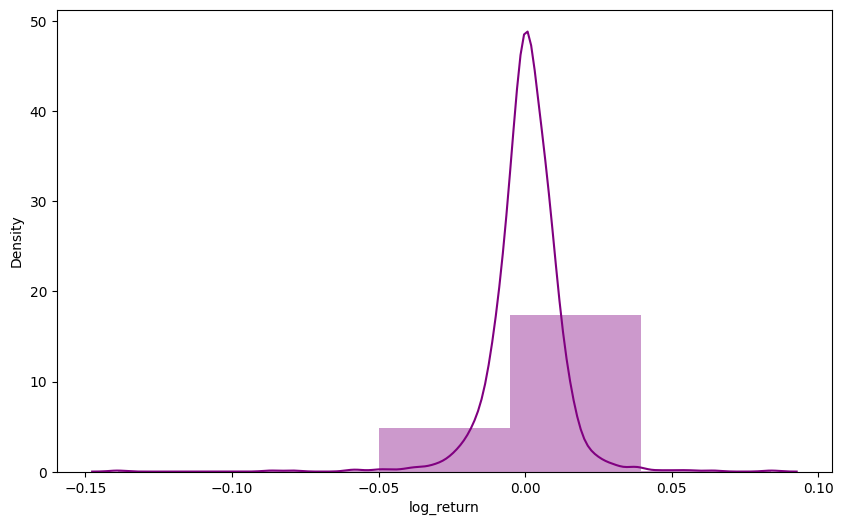

In [96]:
# Coarse histogram (5 bins) of the unconditional return distribution.
# seaborn.distplot is the older name for this density/histogram plot.

plt.figure(figsize=(10,6))
sns.distplot(df['log_return'].dropna(),bins=5,color='purple')
plt.show()


Historical_Volatility per day = 1.33%

In [97]:
# Earlier batch simulator.
# Each batch holds `lookback` days and then fills `prediction_days` steps.
# For each step: volatility and mean of the trailing window, 1,000 standard
# normal draws, the (1 - confidence) percentile of those draws as z, and a
# one-step update of the return path.
# Batch VaR is the same percentile of the simulated portfolio profit-and-loss
# (portfolio_value * simulated log return), here ₹10,00,000 at 99%.

# using historical volatility to predict future volatility using rolling window
import pandas as pd
import numpy as np

def calculate_volatility(data, column_name, lookback_period, prediction_days, portfolio_value, confidence_interval):
    """
    Monte Carlo simulation to calculate volatility and Value at Risk (VaR).
    """
    volatility_dict = {}
    Var_dict = {}
    n = len(data) // (lookback_period + prediction_days)
    j = 0

    while j < n:
        start_index = j * (lookback_period + prediction_days)
        end_index = min((j + 1) * (lookback_period + prediction_days), len(data))
        list1 = data[column_name][start_index:end_index].dropna().tolist()
        historical_volatility = []
        Portfolio_Return = []


        for i in range(lookback_period, lookback_period + prediction_days):
            temp_list = list1[i - lookback_period:i]
            volatility = np.std(temp_list)
            portfolio_expected_return = np.mean(temp_list)
            
        #Z-score calculation
            x= []
            for i in range(1000):
                zscore = np.random.normal(0, 1)
                x.append(zscore)
            z_score = np.percentile(x, 100 * (1 - confidence_interval))
            
        # Predict the next day's return using Monte Carlo
            next_day = list1[-1] * (1 + portfolio_expected_return + volatility * z_score)
            next_day_return = np.log(next_day / list1[-1])  # Logarithmic return
            list1.append(next_day_return)
            historical_volatility.append(volatility)
            
        # Calculate simulated portfolio return
            Portf_Ret = portfolio_value * next_day_return
            Portfolio_Return.append(Portf_Ret)

        # Calculate VaR using simulated portfolio returns
        VaR = np.percentile(Portfolio_Return, 100 * (1 - confidence_interval))
        Var_dict[f'batch{j}'] = VaR

        # Store historical volatility
        volatility_dict[f'predicted_vol{j}'] = historical_volatility
        j += 1

    return volatility_dict, Var_dict


lookback = 90  
predicted_days = 21  
portfolio_value = 1000000  
confidence_interval = 0.99  


volatilities, var_values = calculate_volatility(df, 'log_return', lookback, predicted_days, portfolio_value, confidence_interval)

print('Predicted Volatilities for Each Batch:', volatilities)
print('Value at Risk for Each Batch:', var_values)


Predicted Volatilities for Each Batch: {'predicted_vol0': [0.006526260513593818, 0.0065524083751221365, 0.006461025304998135, 0.006449118174547229, 0.0065631802910810005, 0.006590739363237981, 0.006605593363250068, 0.006656915513964239, 0.006783187582076677, 0.007714768531831391, 0.0076838496470211844, 0.007685603474153381, 0.007728084431462018, 0.007889774760486018, 0.007902140690402392, 0.007887969497807217, 0.007857339969595294, 0.0078831785171396, 0.00784996552238526, 0.007853343906371872, 0.007883582108937382], 'predicted_vol1': [0.010308179809356296, 0.010470242065293596, 0.010383133115944557, 0.010403706334551044, 0.010398214782135177, 0.010424911046366173, 0.01042091260006804, 0.010484446336762442, 0.010479286686008178, 0.01039227036392845, 0.010411693460828784, 0.010412809868028639, 0.01033609109360172, 0.010292946339084688, 0.01029872468633907, 0.010362517225007981, 0.010365090395224562, 0.010369135607492228, 0.010358742060104455, 0.010346057824564818, 0.010340895459089464], 

In [98]:
# Realised portfolio profit-and-loss over each 21-day block, using the
# same ₹10,00,000 scale, so it can be compared with the batch VaR.

lookback = 90  
predicted_days = 21  
portfolio_value = 1000000  
confidence_interval = 0.99 
n = len(data) // (lookback + predicted_days)
act_ret={}
for i in range(n):
    ret=[]
    for j in range((i+1)*lookback,min((i+1)*lookback+predicted_days,len(data))):
        ret.append(portfolio_value*(df['log_return'][j]))
    act_ret[f'batch{i}']=ret
print('Actual Returns for Each Batch:', act_ret)



Actual Returns for Each Batch: {'batch0': [-8689.81466397264, -12114.413370574466, -5087.991559915908, -2028.2814838106026, -11655.673687732526, 6602.542956106478, -5813.4892415846, 8931.937083631537, 13241.31108491434, 36250.386274051205, -10124.42078454291, 2456.6054918568484, -6911.775564206495, 15918.706100504414, 6786.218896810995, 335.38055526396363, -5687.31474540059, 7123.985268305006, -1935.589890696018, 13806.190222918158, -5549.532703580477], 'batch1': [0.0, 2962.96513065727, -4805.059543765006, 8441.164058245833, -6558.172730350039, -17038.966653176176, 2128.519959139933, -12610.718304774393, 51824.69042597882, 28505.409908377584, -1035.0003511433551, -12853.870675538228, 11385.784019294062, -5094.537002551694, -3301.8908183674616, -10033.214077332947, 0.0, -4048.7135163949256, -12384.128036227408, -4336.106053331424, 0.0], 'batch2': [2652.6987005530004, -1538.1131197652744, 987.9023266084048, -254.97969407015808, -10400.103505719097, -4484.643334313313, -5186.043526161765,

In [99]:
# A day in a batch is a violation when realised profit-and-loss is worse
# than that batch's VaR.

violation = {}
for i in range(len(act_ret)):
    for j in range(len(act_ret[f'batch{i}'])):
        if act_ret[f'batch{i}'][j] < var_values[f'batch{i}']:
            violation[f'batch{i}'] = violation.get(f'batch{i}', 0) + 1
print('Number of Violations for Each Batch:', violation)


Number of Violations for Each Batch: {'batch4': 2, 'batch8': 3, 'batch9': 1}


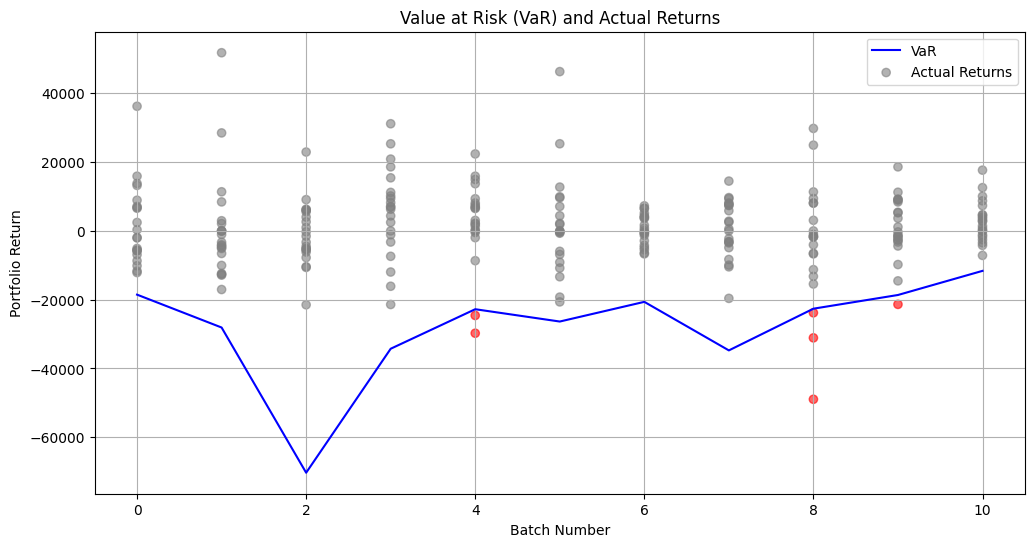

In [100]:
# Blue line: one VaR per batch. Red points: realised days below that VaR.
# Gray points: days inside the threshold.

import matplotlib.pyplot as plt

# Extract VaR values and actual returns
batch_numbers = list(var_values.keys())
var_values_list = list(var_values.values())

# Flatten the actual returns and corresponding batch numbers
actual_returns = []
batch_labels = []
colors = []

for batch, returns in act_ret.items():
    batch_index = int(batch.replace('batch', ''))
    for ret in returns:
        actual_returns.append(ret)
        batch_labels.append(batch_index)
        if ret < var_values[f'batch{batch_index}']:
            colors.append('red')  # Violation of VaR
        else:
            colors.append('gray')  # Normal returns

# Plot the graph
plt.figure(figsize=(12, 6))
plt.plot(range(len(var_values_list)), var_values_list, label="VaR", color='blue', linestyle='-')
plt.scatter(batch_labels, actual_returns, c=colors, alpha=0.6, label="Actual Returns")

# Labels and title
plt.xlabel("Batch Number")
plt.ylabel("Portfolio Return")
plt.title("Value at Risk (VaR) and Actual Returns")
plt.legend(["VaR", "Actual Returns"])
plt.grid(True)
plt.show()


In [101]:
# Violation percentage for the batch design. The 2.4% figure in the report
# comes from the second attempt below, which scores every day rather than
# non-overlapping batches.

# Count total actual returns and violations
total_returns = 0
violations = 0

for batch, returns in act_ret.items():
    batch_index = int(batch.replace('batch', ''))
    var_threshold = var_values[f'batch{batch_index}']
    
    for ret in returns:
        total_returns += 1
        if ret < var_threshold:
            violations += 1

# Calculate the percentage of violations
violation_percentage = (violations / total_returns) * 100

# Print the result
print(f"Total Returns: {total_returns}")
print(f"Total Violations: {violations}")
print(f"Overall Average Percentage of VaR Violations: {violation_percentage:.2f}%")


Total Returns: 231
Total Violations: 6
Overall Average Percentage of VaR Violations: 2.60%


## 2nd attempt ##

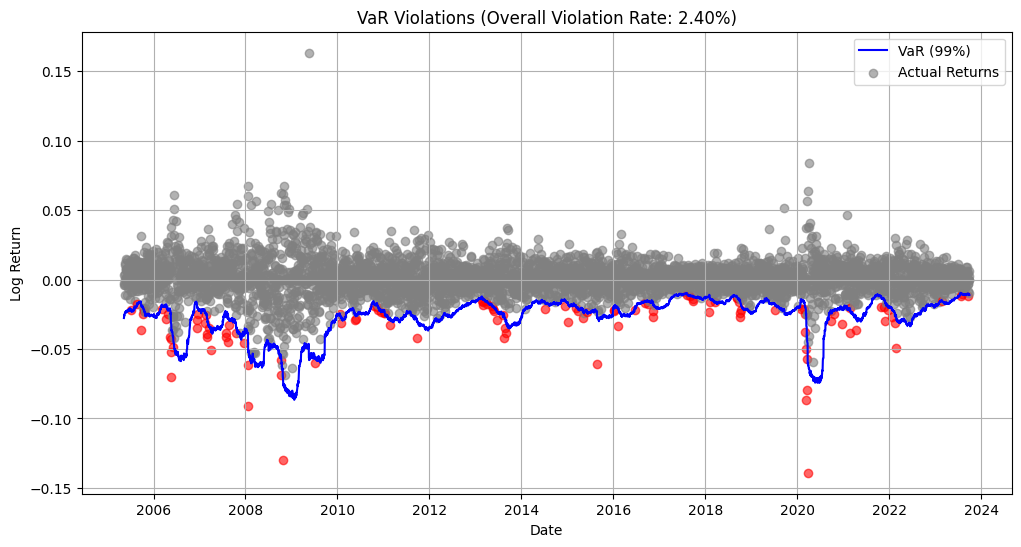

Total Data Points Checked: 4798
Total Violations: 115
Overall Average Percentage of VaR Violations: 2.40%


In [2]:
# Report specification.
# Lookback 90, confidence 99%, 10,000 normal scenarios:
#     R = mu + sigma * z
# VaR = 1st percentile of R.
# The next calendar day's log return is a violation when it is below that VaR.
# Portfolio value is set and is not applied in this version; the comparison
# is in log-return units, which is what the report plots.
# Original path was F:/M.sc/4th sem/FCP/nifty 20 yr.xlsx. This repository
# uses data/Nifty50_data.xlsx (4 Jan 2005 - 25 Sep 2023).

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
file_path = NIFTY_PATH  # was F:/M.sc/4th sem/FCP/nifty 20 yr.xlsx; that file is not in this repo
df = pd.read_excel(file_path)

# Calculate log returns
df['log_return'] = np.log(df['NIFTY Index'] / df['NIFTY Index'].shift(1))

# Parameters
lookback = 90  # Lookback period
confidence_interval = 0.99  # 99% VaR confidence level
portfolio_value = 1000000  # Portfolio value for scaling returns

# Lists to store results
var_values = []
actual_returns = []
violations = []

# Extract valid dates
dates = df['Dates'].iloc[lookback+1:].reset_index(drop=True)  # Ensure proper alignment

# Loop for rolling window
for i in range(lookback, len(df) - 1):  
    # Define lookback window
    past_returns = df['log_return'][i - lookback + 1: i + 1].dropna()

    # Calculate volatility and expected return
    volatility = np.std(past_returns)
    expected_return = np.mean(past_returns)
    
    # Monte Carlo Simulation to determine VaR
    z_scores = np.random.normal(0, 1, 10000)  # Simulating returns
    simulated_returns = expected_return + volatility * z_scores
    VaR = np.percentile(simulated_returns, 100 * (1 - confidence_interval))
    
    # Store VaR
    var_values.append(VaR)
    
    # Check actual return for the next day
    next_day_return = df['log_return'].iloc[i + 1]
    actual_returns.append(next_day_return)
    
    # Check if violation occurs
    violations.append(1 if next_day_return < VaR else 0)

# Compute overall violation percentage
violation_percentage = (sum(violations) / len(violations)) * 100

# Convert dates to NumPy array for proper indexing
dates = np.array(dates)

# Visualization
plt.figure(figsize=(12, 6))
plt.plot(dates, var_values, label="VaR (99%)", color='blue', linestyle='-')

# Scatter plot for actual returns
for i in range(len(actual_returns)):
    color = 'red' if violations[i] else 'gray'
    plt.scatter(dates[i], actual_returns[i], color=color, alpha=0.6)

# Labels and title
plt.xlabel("Date")
plt.ylabel("Log Return")
plt.title(f"VaR Violations (Overall Violation Rate: {violation_percentage:.2f}%)")
plt.legend(["VaR (99%)", "Actual Returns"])
plt.grid(True)
plt.show()

# Print violation statistics
print(f"Total Data Points Checked: {len(violations)}")
print(f"Total Violations: {sum(violations)}")
print(f"Overall Average Percentage of VaR Violations: {violation_percentage:.2f}%")


In [3]:
# Same three backtests as the other notebooks, applied to the 0/1 violation
# list from the cell above.
# Kupiec checks the 1% breach rate. Christoffersen checks clustering.
# Conditional coverage adds the two likelihood ratios.

import scipy.stats as stats
import numpy as np

# Kupiec's Proportion of Failures (POF) Test
def kupiec_pof_test(violations, confidence_level, total_observations):
    p = 1 - confidence_level  # Expected violation probability
    x = sum(violations)  # Observed violations
    q = 1 - p  # Probability of non-violations
    
    likelihood_h0 = (p ** x) * (q ** (total_observations - x))
    likelihood_h1 = ((x / total_observations) ** x) * ((1 - x / total_observations) ** (total_observations - x))
    
    likelihood_ratio = -2 * np.log(likelihood_h0 / likelihood_h1)
    p_value = 1 - stats.chi2.cdf(likelihood_ratio, df=1)
    
    return likelihood_ratio, p_value

# Christoffersen's Independence Test
def christoffersen_independence_test(violations):
    n00, n01, n10, n11 = 0, 0, 0, 0
    for i in range(1, len(violations)):
        if violations[i - 1] == 0 and violations[i] == 0:
            n00 += 1
        elif violations[i - 1] == 0 and violations[i] == 1:
            n01 += 1
        elif violations[i - 1] == 1 and violations[i] == 0:
            n10 += 1
        elif violations[i - 1] == 1 and violations[i] == 1:
            n11 += 1
    
    pi0 = n01 / (n00 + n01) if (n00 + n01) > 0 else 0
    pi1 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    
    likelihood_h0 = ((pi ** (n01 + n11)) * ((1 - pi) ** (n00 + n10)))
    likelihood_h1 = ((pi0 ** n01) * ((1 - pi0) ** n00) * (pi1 ** n11) * ((1 - pi1) ** n10))
    
    likelihood_ratio = -2 * np.log(likelihood_h0 / likelihood_h1)
    p_value = 1 - stats.chi2.cdf(likelihood_ratio, df=1)
    
    return likelihood_ratio, p_value

# Joint Conditional Coverage (Christoffersen's Combined Test)
def joint_conditional_coverage_test(pof_lr, pof_p, ind_lr, ind_p):
    joint_lr = pof_lr + ind_lr  # Sum of the likelihood ratios
    p_value = 1 - stats.chi2.cdf(joint_lr, df=2)
    return joint_lr, p_value

# Run tests
pof_lr, pof_p = kupiec_pof_test(violations, confidence_interval, len(violations))
ind_lr, ind_p = christoffersen_independence_test(violations)
joint_lr, joint_p = joint_conditional_coverage_test(pof_lr, pof_p, ind_lr, ind_p)

# Print results
print(f"Kupiec POF Test: LR = {pof_lr:.4f}, p-value = {pof_p:.4f}")
print(f"Christoffersen Independence Test: LR = {ind_lr:.4f}, p-value = {ind_p:.4f}")
print(f"Joint Conditional Coverage Test: LR = {joint_lr:.4f}, p-value = {joint_p:.4f}")


Kupiec POF Test: LR = 67.9641, p-value = 0.0000
Christoffersen Independence Test: LR = 7.0627, p-value = 0.0079
Joint Conditional Coverage Test: LR = 75.0268, p-value = 0.0000
